# Lipschitz toy model testin

Following will be a series of tests to see how the performance of the Lipschitz constrained model acts.

In [1]:
import os
import sys
import random
import numpy as np
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import tqdm

import monotonicnetworks as lmn

import matplotlib.pyplot as plt


In [2]:
# "Homemade" modules
from models import UnconstrainedModel, LipschitzModel
from train_eval import train, evaluate, predict


## Sine function

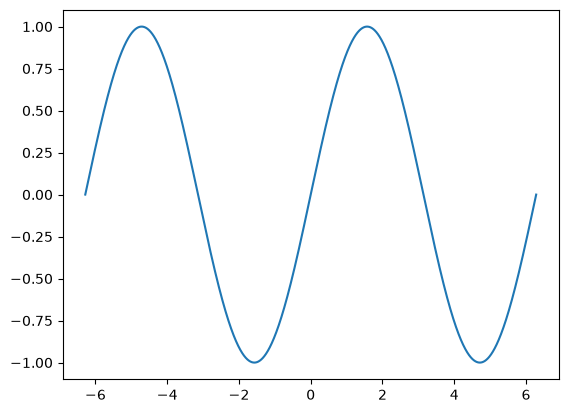

In [3]:
# Sine function
x = np.linspace(-2*np.pi, 2*np.pi, 10000)
sine_func = np.sin(x)

plt.plot(x, sine_func)
plt.show()

In [10]:
# HYPERPARAMETERS
HIDDEN_DIM = 10
N_GROUPS = 2
DEPTH = 3
LEARNING_RATE = 0.01
NUM_EPOCHS = 1000

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Network
Lipschitz_1_model = LipschitzModel(input_dim=1, hidden_dim=10, output_dim=1, n_groups=2, depth = 3, lipschitz_bound=1)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(Lipschitz_1_model.parameters(), lr=0.01)

In [11]:
# Data
train_data, val_data = train_test_split(sine_func, test_size=0.2, random_state=42)

# Dataset
train_dataset = torch.utils.data.TensorDataset(torch.tensor(train_data[:-1]).float().unsqueeze(1), torch.tensor(train_data[1:]).float().unsqueeze(1))
val_dataset = torch.utils.data.TensorDataset(torch.tensor(val_data[:-1]).float().unsqueeze(1), torch.tensor(val_data[1:]).float().unsqueeze(1))


# Dataloader
trn_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)


In [12]:
train_losses_L1, val_losses_L1 = train(model =Lipschitz_1_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    optimizer = optimizer,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    device = device)

Epoch 1
-------------------------------
Epoch 2
-------------------------------
Epoch 3
-------------------------------
Epoch 4
-------------------------------
Epoch 5
-------------------------------
Epoch 6
-------------------------------
Epoch 7
-------------------------------
Epoch 8
-------------------------------
Epoch 9
-------------------------------
Epoch 10
-------------------------------
Epoch 11
-------------------------------
Epoch 12
-------------------------------
Epoch 13
-------------------------------
Epoch 14
-------------------------------
Epoch 15
-------------------------------
Epoch 16
-------------------------------
Epoch 17
-------------------------------
Epoch 18
-------------------------------
Epoch 19
-------------------------------
Epoch 20
-------------------------------
Epoch 21
-------------------------------
Epoch 22
-------------------------------
Epoch 23
-------------------------------
Epoch 24
-------------------------------
Epoch 25
----------------

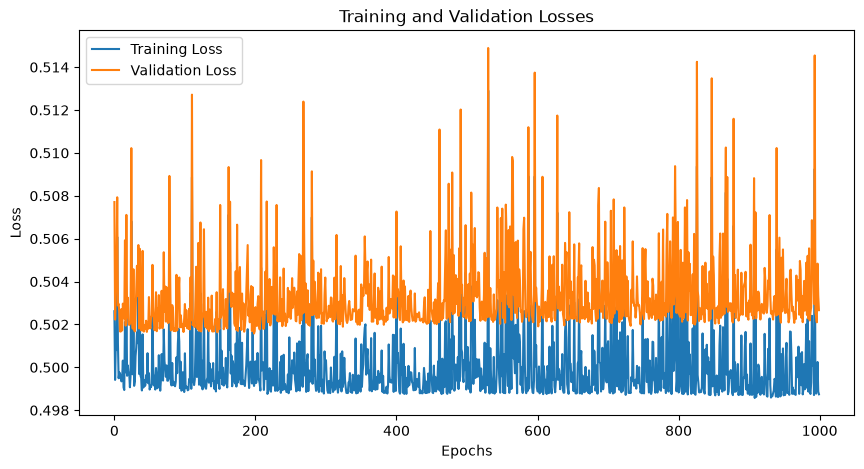

In [13]:
# Plotting training and validation losses
plt.figure(figsize=(10, 5))
plt.plot(train_losses_L1, label='Training Loss')
plt.plot(val_losses_L1, label='Validation Loss')
plt.title('Training and Validation Losses')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

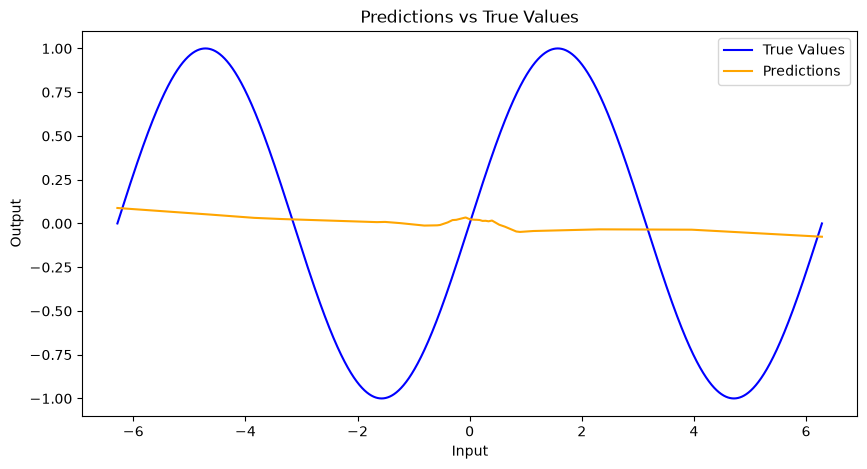

In [21]:
# Plotting predictions

dataloader = DataLoader(torch.tensor(x).float().unsqueeze(1), batch_size=32, shuffle=False)
y = np.sin(x)
predictions_1_lipschitz = Lipschitz_1_model(torch.tensor(x).float().unsqueeze(1)).detach().numpy()
#predict(Lipschitz_1_model, torch.Tensor(x).unsqueeze(-1), device)

plt.figure(figsize=(10, 5))
plt.plot(x, y, label='True Values', color='blue')
plt.plot(x, predictions_1_lipschitz, label='Predictions', color='orange')
plt.title('Predictions vs True Values')
plt.xlabel('Input')
plt.ylabel('Output')
plt.legend()
plt.show()

## Gaussian function